# Worry-only and worry–harm clusters on matched respondents

The four-cluster worry-only model covers 2019–2025 and meets the original 40% size limit. The main worry–harm model has five clusters and covers 2021–2025. We first compare their labels on the same respondents. We then fit models with the same worry questions and number of clusters to measure the change when harm is added. A final comparison shows how the harm cluster draws from all four worry-only groups.

**Run All** checks the stored evidence and regenerates the tables and figure. No raw data or refitting is required for this replay. The optional fitting section uses the original survey CSVs and is switched off by default.

In [1]:
from pathlib import Path
from itertools import combinations, product
import hashlib
import json
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
from sklearn.metrics import adjusted_rand_score
from IPython.display import display

assets=next(folder/'assets' for cwd in [Path.cwd(),*Path.cwd().parents]
            for folder in [cwd,cwd/'paper',cwd/'github_publication/paper']
            if (folder/'assets/worry_harm_comparison_manifest.json').is_file())
manifest=json.loads((assets/'worry_harm_comparison_manifest.json').read_text())
for path,h in manifest['files_sha256'].items():
    assert hashlib.sha256((assets/path).read_bytes()).hexdigest()==h
worry=json.loads((assets/'shared_worry_strict40_report.json').read_text())
comparison=json.loads((assets/'worry_harm_comparison.json').read_text())
full=json.loads((assets/'shared_five_report.json').read_text())
c_wory=json.loads((assets/'shared_worry_only_conditions.json').read_text())
c_full=json.loads((assets/'shared_five_rule_conditions.json').read_text())

In [2]:
def take(path):
    with np.load(path,allow_pickle=False) as z:
        return {k:z[k] for k in z.files}

def worry_tree(x,n=4):
    parent=np.where(x[:,2]==0,1,np.where(x[:,1]==0,0,2))
    return np.where((parent==2)&(x[:,4]==0),3,parent) if n==4 else parent

def align(a,b,mass,k):
    table=np.bincount(k*a+b,weights=mass,minlength=k*k).reshape(k,k)
    i,j=linear_sum_assignment(-table)
    m=np.empty(k,int)
    m[j]=i
    return m[b]

def worry_geometry(x,q=.75,lam=1.5):
    v=np.where(x==2,1.,np.where(x==1,q,0.))
    m=v.mean(1,keepdims=True)
    return np.column_stack([v-m,np.sqrt(lam)*m])/np.sqrt(5)

def full_geometry(x):
    v=np.where(x[:,:6]==2,1.,np.where(x[:,:6]==1,1/3,0.))
    m=v.mean(1,keepdims=True)
    return np.column_stack([(v-m)*np.sqrt(.625/6),m*np.sqrt(.625/6),x[:,6:]*np.sqrt(.375/14),np.zeros(len(x))])

def condition_mask(x,conditions,rule,domains):
    w=x[:,:domains]
    counts={'very':(w==2).sum(1),'not':(w==0).sum(1),'some':(w>=1).sum(1)}
    if domains==6:
        counts.update(known=x[:,6:13].sum(1),personal=x[:,13:20].sum(1))
    ops={'eq':np.equal,'le':np.less_equal,'ge':np.greater_equal}
    masks=np.column_stack([ops[t['op']](x[:,t['j']] if 'j' in t else counts[t['base']],t['value'])
                            for t in conditions])
    return np.logical_or.reduce([masks[:,p].all(axis=1) for p in rule['clauses']])

def overlap(a,b,mass):
    return np.bincount(5*a+b,weights=mass,minlength=20).reshape(4,5)

def comparison_metrics(weighted):
    p=weighted/weighted.sum()
    w=p.sum(1);f=p.sum(0)
    mask=p>0
    hfw=np.sum(p[mask]*np.log2(np.broadcast_to(w[:,None],p.shape)[mask]/p[mask]))
    hwf=np.sum(p[mask]*np.log2(np.broadcast_to(f[None,:],p.shape)[mask]/p[mask]))
    return dict(full_given_worry=float(hfw),worry_given_full=float(hwf),
         variation_information=float(hfw+hwf),H_worry=float(-np.sum(w*np.log2(w))),
         H_full=float(-np.sum(f*np.log2(f))),worry_to_full_modal=float(p.max(1).sum()),
         full_to_worry_modal=float(p.max(0).sum()))

def rule_quality(rule_mask,target,weight):
    common=weight[rule_mask&target].sum()
    return dict(rule_mass=float(weight[rule_mask].sum()),precision=float(common/weight[rule_mask].sum()),
                coverage=float(common/weight[target].sum()))

def mask_jaccard(rows,columns,mass):
    table=np.empty((len(rows),len(columns)))
    for i,a in enumerate(rows):
        for j,b in enumerate(columns):
            table[i,j]=mass[a&b].sum()/mass[a|b].sum()
    return table

## Four worry-only clusters under the original size cap

Weighted \(k\)-means first fits three centres using five worry values \(0,0.75,1\), five differences from their mean, and a separate mean coordinate weighted by \(\sqrt{1.5}\). It then fits two centres inside the group with both crime and water worry. This fit uses differences from the mean of the same five answers and leaves out the mean coordinate. Both stages are fitted separately in each wave.

The selected point assignment is exact on all 243 complete patterns: no crime worry gives C1; crime worry without water worry gives C0; when both are present, no mental-health worry gives C3 and mental-health worry gives C2. Each of two fresh batches has 50 respondent refits and 50 country refits per wave. One refit per batch recovered a different partition. The next cell checks every fit. The earlier batch stores the first-stage output and the second-stage centres. The later batch also stores the first-stage centres.

In [3]:
study=take(assets/'shared_worry_strict40_evidence.npz')
wref=take(assets/'reference_common_worry.npz')
x=study['answers']
assert np.array_equal(x,wref['answers'])
mass=study['worry_ref_mass']
counts=wref['counts'][3]
native=study['native_mass']
parent=worry_tree(x,3)
tree=worry_tree(x)
first=worry_geometry(x)
child=worry_geometry(x,lam=0.)
check=[]
for batch in ['earlier','later']:
    recorded=study[f'{batch}_fit_labels']
    assert recorded.shape==(4,101,243)
    fixed=np.empty_like(recorded)
    for i,j in product(range(4),range(101)):
        if batch=='earlier':
            p=study['earlier_parent_labels'][i,j].copy()
        else:
            label=cdist(first,study['later_parent_centres'][i,j]).argmin(1)
            p=align(parent,label,mass,3)
        cut=p==2
        p[cut]=2+cdist(child,study[f'{batch}_child_centres'][i,j]).argmin(1)[cut]
        np.testing.assert_array_equal(p,recorded[i,j])
        fixed[i,j]=align(tree,p,mass,4)
    assert np.array_equal(fixed[:,0],np.broadcast_to(tree,(4,243)))
    n=sum(np.array_equal(run,tree) for run in fixed[:,1:].reshape(-1,243))
    assert n==399
    pairs=[]
    for a,b in combinations(range(4),2):
        for group in [slice(1,51),slice(51,101)]:
            scores=[];jacc=[]
            for left,right in product(fixed[a,group],fixed[b,group]):
                if np.array_equal(left,right):
                    scores.append(1.)
                    jacc.append(np.ones(4))
                    continue
                scores.append(adjusted_rand_score(np.repeat(left,counts),np.repeat(right,counts)))
                w=np.bincount(4*left+right,weights=mass,minlength=16).reshape(4,4)
                hit=np.diag(w)
                jacc.append(hit/(w.sum(1)+w.sum(0)-hit))
            assert len(scores)==2500
            pairs.append((min(scores),np.quantile(scores,.10),np.quantile(jacc,.10,axis=0).min()))
    v=np.min(pairs,axis=0)
    np.testing.assert_allclose(v,[.4216811055661955,1.,1.],atol=1e-12)
    check.append(dict(batch=batch,exact_point_fits=4,exact_refits=n,refits=400,
                      minimum_ARI=v[0],minimum_p10_ARI=v[1],minimum_p10_Jaccard=v[2]))
display(pd.DataFrame(check).round(4))
shares=np.asarray([np.bincount(tree,weights=w,minlength=4) for w in native])
np.testing.assert_allclose(shares,worry['native_shares'],atol=1e-12)
assert shares.max()<.40
display(pd.DataFrame(shares.T,index=worry['names'],columns=worry['waves']).mul(100).round(2))

,batch,exact_point_fits,exact_refits,refits,minimum_ARI,minimum_p10_ARI,minimum_p10_Jaccard
0,earlier,4,399,400,0.4217,1.0,1.0
1,later,4,399,400,0.4217,1.0,1.0


,2019,2021,2023,2025
Crime worry without water worry,27.55,27.86,29.42,28.20
No crime worry,27.82,34.68,33.45,32.85
"Crime, water and mental-health worry",30.38,26.57,26.53,27.27
Crime and water worry without mental-health worry,14.25,10.89,10.60,11.67


## Agreement between the two clusterings

Use each wave's own point fit on complete answers from the same 92 development countries. ARI uses counts of respondents. The overlap table gives each country equal total weight while retaining survey weights within countries. The row distributions average to \(H(F\mid W)\), the weighted conditional entropy of the worry–harm label given the worry-only label. The column distributions give \(H(W\mid F)\). A zero conditional entropy would indicate a deterministic mapping in that direction.

We compare the short rules separately. For each pair of rules, weighted Jaccard is the weight matching both divided by the weight matching either. This compares their match sets instead of the fitted assignments.

In [4]:
ref=take(assets/'reference_full.npz')
five=take(assets/'shared_five_evidence.npz')
X=ref['answers']
p5=X[:,[0,1,2,3,5]]
wlabel=worry_tree(p5)
cond_x=X[:,[*range(6),*range(13,20),*range(6,13)]]
Z=full_geometry(X)
metrics=[]
for i,y in enumerate([2021,2023,2025]):
    flabel=five[f'{y}_centre_to_cluster'][cdist(Z,five[f'{y}_centres']).argmin(1)]
    n=ref['counts'][i]
    w=ref['masses'][i]/ref['masses'][i].sum()
    observed=overlap(wlabel,flabel,w)
    row=dict(wave=y,n=n.sum(),ARI=adjusted_rand_score(np.repeat(wlabel,n),np.repeat(flabel,n)),
             **comparison_metrics(observed))
    expected=comparison['metrics'][i]
    for key in row:
        np.testing.assert_allclose(row[key],expected[key],atol=1e-12)
    metrics.append(row)
    a=[condition_mask(p5,c_wory,o['formula'],5) for o in worry['rules']]
    b=[condition_mask(cond_x,c_full,c['rule']['canonical'],6) for c in full['models'][f'full_{y}']['clusters']]
    jaccard=mask_jaccard(a,b,w)
    data=comparison['by_year'][str(y)]
    np.testing.assert_allclose(observed,data['weighted'],atol=1e-12)
    np.testing.assert_allclose(jaccard,data['rule_jaccard'],atol=1e-12)
    if y==2025:
        membership=100*observed/observed.sum(1)[:,None]
        rule_overlap=jaccard
display(pd.DataFrame(metrics)[['wave','n','ARI','full_given_worry','worry_given_full','variation_information']].round(4))
print('2025 membership overlap, % within each worry-only cluster')
display(pd.DataFrame(membership,index=worry['names'],columns=full['names']).round(2))
print('2025 weighted Jaccard for the short rule match sets')
display(pd.DataFrame(rule_overlap,index=worry['names'],columns=full['names']).round(4))

2025 membership overlap, % within each worry-only cluster
2025 weighted Jaccard for the short rule match sets


,wave,n,ARI,full_given_worry,worry_given_full,variation_information
0,2021,90322,0.1642,1.7756,1.5519,3.3274
1,2023,90091,0.1413,1.7879,1.5709,3.3589
2,2025,90395,0.1432,1.7847,1.6070,3.3917


,External hazards,Basic necessities,Mental-health worry,Harm to people they know,Few very high worries
Crime worry without water worry,44.47,0.01,18.02,4.98,32.53
No crime worry,17.98,6.27,4.89,3.65,67.22
"Crime, water and mental-health worry",22.73,27.35,17.85,20.21,11.86
Crime and water worry without mental-health worry,48.32,24.10,0.00,7.39,20.19


,External hazards,Basic necessities,Mental-health worry,Harm to people they know,Few very high worries
Crime worry without water worry,0.2901,0.0000,0.1505,0.0287,0.1731
No crime worry,0.1128,0.0319,0.0461,0.0220,0.4580
"Crime, water and mental-health worry",0.1317,0.2690,0.1435,0.1630,0.0767
Crime and water worry without mental-health worry,0.1321,0.1328,0.0000,0.0646,0.0587


No crime worry overlaps most closely with few very high worries. The assignments still differ substantially, and even this pair of short descriptions has Jaccard overlap of only about 0.46. The analysis compares two learned representations. Differences reflect the inputs and fitting choices together.

## Adding harm with the worry questions and cluster count fixed

For each of 2021, 2023 and 2025, use native development respondents with complete answers to the full question set. Fit a pair of weighted \(k\)-means models on those same respondents. Both use the same worry questions, worry coding and \(k\). One also uses the fourteen harm indicators, seven for harm to self and seven for harm to people the respondent knows. The primary pair uses six worries and five clusters. Repeat with four clusters and with the five common worries, which omit traffic.

Code the \(d\) worry answers \(x\) as \(0,1/3,1\). Write \(m\) for their mean for each respondent. Both fits use \(\sqrt{0.625/d}\,(x-m\mathbf{1},m)\). The worry–harm fit appends the fourteen indicators scaled by \(\sqrt{0.375/14}\). Use equal total weight per country and retain relative survey weights within countries.

The matched ARI compares the two fits on the same complete respondents in each wave in the 92 common development countries. For the refit check, compare the two models from the same draw. Each wave has 50 respondent draws and 50 country draws. The two arms share the draw and fit seeds.

Stability asks a separate question. For each arm, compare independently fitted waves on the same 90,395 complete 2025 respondents. Align the wave labels to the 2025 point fit by maximum weighted overlap, then align each refit to its wave’s point fit. Calculate ARI from respondent counts and Jaccard from country-balanced survey weights. Each within-wave ARI distribution uses all 1,225 distinct refit pairs on its native development sample. Each cross-wave distribution uses all 2,500 pairs of the same refit type. The stability table reports the lowest tenth percentiles and the largest native cluster share. The cluster table shows the lowest tenth-percentile Jaccard for each 2025-aligned cluster.

In [5]:
paper_dir = assets.parent
matched_manifest = json.loads((assets / 'matched_harm_manifest.json').read_text())
for name, expected_hash in matched_manifest['files_sha256'].items():
    assert hashlib.sha256((paper_dir / name).read_bytes()).hexdigest() == expected_hash, name

matched_centres = take(assets / 'matched_harm_centres.npz')
matched_years = (2021, 2023, 2025)
refit_types = ('respondents', 'countries')
worry_columns = {6: (0, 1, 2, 3, 4, 5), 5: (0, 1, 2, 3, 5)}
matched_settings = list(product((6, 5), (5, 4), (False, True)))


def setting_name(d, k, use_harm):
    inputs = 'harm' if use_harm else 'worry'
    return f'{d}q_k{k}_{inputs}'


def matched_geometry(answers, d, use_harm):
    ordinal = np.array([0., 1/3, 1.])[answers[:, worry_columns[d]]]
    mean = ordinal.mean(axis=1, keepdims=True)
    worry_design = np.column_stack((ordinal - mean, mean)) * np.sqrt(.625 / d)
    if use_harm:
        harm_design = answers[:, 6:] * np.sqrt(.375 / 14)
        return np.column_stack((worry_design, harm_design))
    return worry_design


def nearest(design, centres):
    return cdist(design, centres, metric='sqeuclidean').argmin(axis=1).astype(np.int8)


def label_table(a, b, weights, k):
    key = k * a.astype(int) + b
    return np.bincount(key, weights=weights, minlength=k*k).reshape(k, k)


def ari_from_counts(counts):
    def pairs(n):
        return (n * (n - 1) / 2).sum()

    same_left = pairs(counts.sum(axis=1))
    same_right = pairs(counts.sum(axis=0))
    expected = same_left * same_right / pairs(counts.sum())
    maximum = (same_left + same_right) / 2
    if maximum == expected:
        return 1.
    return (pairs(counts) - expected) / (maximum - expected)


def weighted_jaccard(table):
    both = table.diagonal()
    either = table.sum(axis=1) + table.sum(axis=0) - both
    return np.divide(both, either, out=np.zeros_like(both), where=either > 0)


def label_map(target, proposed, weights, k):
    rows, cols = linear_sum_assignment(-label_table(target, proposed, weights, k))
    mapping = np.empty(k, dtype=np.int8)
    mapping[cols] = rows
    return mapping


def distribution(scores):
    keys = ('min', 'p10', 'median', 'p90', 'max')
    return dict(zip(keys, np.quantile(scores, (0, .1, .5, .9, 1))))


def refit_pair_scores(left, right, counts, k, weights=None):
    """Compare all model pairs, using each within-wave pair once."""
    within_wave = right is None
    runs = left if within_wave else np.concatenate((left, right))

    # Answer patterns with identical labels in every run can share one row.
    signatures = np.ascontiguousarray(runs.T)
    keys = signatures.view(np.dtype((np.void, signatures.shape[1]))).ravel()
    _, first, inverse = np.unique(keys, return_index=True, return_inverse=True)
    runs = runs[:, first]
    counts = np.bincount(inverse, weights=counts)
    if weights is not None:
        weights = np.bincount(inverse, weights=weights)

    pairs = (combinations(range(len(left)), 2) if within_wave
             else product(range(len(left)), range(len(left), len(runs))))
    scores, recovery = [], []
    for i, j in pairs:
        a, b = runs[i], runs[j]
        scores.append(ari_from_counts(label_table(a, b, counts, k)))
        if weights is not None:
            recovery.append(weighted_jaccard(label_table(a, b, weights, k)))
    assert len(scores) == (1225 if within_wave else 2500)
    return np.array(scores), np.array(recovery)


def replay_matched_fits(centres):
    shared_counts = ref['counts'][-1]
    shared_mass = ref['masses'][-1]
    on_reference = shared_counts > 0
    # Use all three waves' answer patterns for the paired, same-wave comparisons.
    point_labels, refit_labels = {}, {}
    summaries, cluster_rows = [], []
    for d, k, use_harm in matched_settings:
        name = setting_name(d, k, use_harm)
        evaluation = matched_geometry(ref['answers'], d, use_harm)
        point = {year: nearest(evaluation, centres[f'{name}_{year}_point'][0])
                 for year in matched_years}
        to_2025 = {year: label_map(point[2025][on_reference], point[year][on_reference],
                                   shared_mass[on_reference], k) for year in matched_years}
        point_labels[name] = point
        refit_labels[name] = {}
        cross_point_scores = [ari_from_counts(label_table(point[a], point[b], shared_counts, k))
                              for a, b in combinations(matched_years, 2)]
        largest_shares, within_p10, cross_p10, cluster_p10 = [], [], [], []
        aligned_by_test = {test: {} for test in refit_types}
        for year in matched_years:
            native = matched_geometry(five[f'native_{year}_answers'], d, use_harm)
            native_point = nearest(native, centres[f'{name}_{year}_point'][0])
            largest_shares.append(np.bincount(native_point, weights=five[f'native_{year}_mass']).max())
            for test in refit_types:
                fitted = centres[f'{name}_{year}_{test}']
                predictions = np.stack([nearest(evaluation, centre) for centre in fitted])
                refit_labels[name][year, test] = predictions
                shared_predictions = predictions[:, on_reference]
                aligned = []
                for labels in shared_predictions:
                    to_point = label_map(point[year][on_reference], labels, shared_mass[on_reference], k)
                    aligned.append(to_2025[year][to_point[labels]])
                aligned_by_test[test][year] = np.stack(aligned)
                native_labels = np.stack([nearest(native, centre) for centre in fitted])
                scores, _ = refit_pair_scores(native_labels, None, five[f'native_{year}_counts'], k)
                within_p10.append(np.quantile(scores, .1))
        for test, aligned in aligned_by_test.items():
            for a, b in combinations(matched_years, 2):
                scores, jaccard = refit_pair_scores(aligned[a], aligned[b], shared_counts[on_reference], k,
                                                   shared_mass[on_reference])
                cross_p10.append(np.quantile(scores, .1))
                cluster_p10.append(np.quantile(jaccard, .1, axis=0).min())
                for cluster, values in enumerate(jaccard.T):
                    cluster_rows.append(dict(specification=name, year_a=a, year_b=b, test=test,
                                             cluster=cluster, **distribution(values)))
        summaries.append(dict(specification=name, min_cross_point_ARI=min(cross_point_scores),
                              max_native_share=max(largest_shares), min_within_p10_ARI=min(within_p10),
                              min_cross_p10_ARI=min(cross_p10), min_cross_p10_Jaccard=min(cluster_p10)))

    paired = []
    for d, k in product((6, 5), (5, 4)):
        a, b = (setting_name(d, k, harm) for harm in (False, True))
        for i, year in enumerate(matched_years):
            counts = ref['counts'][i]
            row = dict(worry_questions=d, clusters=k, year=year)
            point_ari = ari_from_counts(label_table(point_labels[a][year], point_labels[b][year], counts, k))
            paired.append(dict(**row, test='point', ARI=point_ari))
            for test in refit_types:
                # Compare the two arms on the same draw, with the same draw index.
                left, right = refit_labels[a][year, test], refit_labels[b][year, test]
                scores = [ari_from_counts(label_table(x, y, counts, k)) for x, y in zip(left, right)]
                paired.append(dict(**row, test=test, **distribution(scores)))
    return pd.DataFrame(paired), pd.DataFrame(summaries), pd.DataFrame(cluster_rows)


paired_ari, matched_stability, cluster_stability = replay_matched_fits(matched_centres)
for name, observed, order in [
    ('ari', paired_ari, ['worry_questions', 'clusters', 'year', 'test']),
    ('stability', matched_stability, ['specification']),
    ('cluster_stability', cluster_stability, ['specification', 'year_a', 'year_b', 'test', 'cluster']),
]:
    saved = pd.read_csv(paper_dir / 'results' / f'matched_harm_{name}.csv')
    pd.testing.assert_frame_equal(observed[saved.columns].sort_values(order).reset_index(drop=True),
                                  saved.sort_values(order).reset_index(drop=True),
                                  check_dtype=False, rtol=1e-10, atol=1e-12)

print('Same-wave ARI when the harm block is added')
display(paired_ari.query("test == 'point'").pivot(index=['worry_questions', 'clusters'], columns='year',
                                                 values='ARI').sort_index(ascending=False).round(3))
print('Six worries and five clusters, paired refit ARI')
display(paired_ari.query("worry_questions == 6 and clusters == 5 and test != 'point'")
        [['year', 'test', 'p10', 'median', 'p90']].round(3).reset_index(drop=True))
print('Worst case across the waves and refit types for each matched setting')
display(matched_stability.assign(max_native_share=lambda df: 100 * df.max_native_share)
        .rename(columns={'max_native_share':'max_native_share_pct'}).round(3))
print('Lowest cross-wave lower-decile Jaccard for each cluster')
display(cluster_stability.groupby(['specification', 'cluster']).p10.min().unstack().round(3))

Same-wave ARI when the harm block is added
Six worries and five clusters, paired refit ARI
Worst case across the waves and refit types for each matched setting
Lowest cross-wave lower-decile Jaccard for each cluster


year                       2021   2023   2025
worry_questions clusters                     
6               5         0.815  0.882  0.496
                4         0.909  0.884  0.857
5               5         0.921  0.916  0.891
                4         0.918  0.887  0.909

,year,test,p10,median,p90
0,2021,respondents,0.822,0.899,0.905
1,2021,countries,0.818,0.898,0.905
2,2023,respondents,0.675,0.881,0.884
3,2023,countries,0.670,0.876,0.884
4,2025,respondents,0.491,0.500,0.685
5,2025,countries,0.490,0.519,0.707


,specification,min_cross_point_ARI,max_native_share_pct,min_within_p10_ARI,min_cross_p10_ARI,min_cross_p10_Jaccard
0,6q_k5_worry,0.978,42.905,0.677,0.669,0.194
1,6q_k5_harm,0.531,40.879,0.511,0.522,0.009
2,6q_k4_worry,0.624,45.457,0.618,0.506,0.103
3,6q_k4_harm,0.632,43.293,0.617,0.468,0.110
4,5q_k5_worry,0.879,45.734,0.904,0.858,0.474
5,5q_k5_harm,0.892,43.897,0.897,0.883,0.478
6,5q_k4_worry,0.631,51.168,0.616,0.626,0.106
7,5q_k4_harm,0.651,49.340,0.637,0.639,0.285


cluster,0,1,2,3,4
specification,,,,,
5q_k4_harm,0.838,0.498,0.819,0.285,NaN
5q_k4_worry,0.106,0.799,0.476,0.803,NaN
5q_k5_harm,0.478,0.955,0.545,0.978,0.830
5q_k5_worry,0.967,0.545,0.474,0.895,0.752
6q_k4_harm,0.823,0.110,0.687,0.221,NaN
6q_k4_worry,0.820,0.241,0.721,0.103,NaN
6q_k5_harm,0.770,0.009,0.582,0.199,0.281
6q_k5_worry,0.194,0.279,0.902,0.822,0.774


Eleven of the twelve point comparisons gave ARI above 0.80. The exception was 2025 with six worries and five clusters. Its ARI was 0.496, and the median paired refit ARIs were about 0.50 for respondent draws and 0.52 for country draws. All eight specifications exceeded the 40% size limit in at least one wave and had at least one cross-wave cluster Jaccard below 0.80 at the tenth percentile.

## The harm cluster cuts across the four worry-only groups

Return to the main five- and four-cluster models. Choose the pair of worry–harm groups to merge, and the label match for the resulting four groups, by maximum weighted agreement on 2025. Use that same merge and match for 2021 and 2023. A single split of a worry-only cluster would allow a merge giving full agreement. The best 2025 merge gives about 48–51% across the three waves.

To check whether the redistribution itself recurs, apply each wave’s point models to the same 2025 reference answers. Compare the four-by-five overlap tables by total variation, half the sum of the absolute differences in their weighted cell shares. With the worry-only assignment fixed, repeat with the archived worry–harm refits. Figure 3 answers a related question on each wave’s own matched respondents. Each bar is the entire **Harm to people they know** cluster, divided by its members’ worry-only assignments.

In [6]:
import matplotlib.pyplot as plt


full_labels = {
    year: five[f'{year}_centre_to_cluster'][nearest(Z, five[f'{year}_centres'])]
    for year in matched_years
}
reference_mass = ref['masses'][-1]
reference_counts = ref['counts'][-1]
in_2025 = reference_counts > 0
reference_mass = reference_mass / reference_mass.sum()
overlap_2025 = overlap(wlabel, full_labels[2025], reference_mass)


def best_single_merge():
    options = []
    for first, second in combinations(range(5), 2):
        merge = np.arange(5)
        merge[second] = first
        _, codes = np.unique(merge, return_inverse=True)
        relabel = label_map(wlabel, codes[full_labels[2025]], reference_mass, 4)
        mapping = relabel[codes]
        agreement = reference_mass[mapping[full_labels[2025]] == wlabel].sum()
        options.append((agreement, first, second, mapping))
    return max(options, key=lambda option: option[0])[1:]


merge_first, merge_second, merge_map = best_single_merge()
composition, redistribution, refit_distances = [], [], []
for i, year in enumerate(matched_years):
    weights = ref['masses'][i] / ref['masses'][i].sum()
    labels = full_labels[year]
    by_wave = overlap(wlabel, labels, weights)
    on_2025 = overlap(wlabel, labels, reference_mass)
    harm = by_wave[:, 3]
    composition.append(harm / harm.sum())
    merged = label_table(wlabel, merge_map[labels], weights, 4)
    redistribution.append(dict(year=year, merge_first=merge_first, merge_second=merge_second,
        best_row_modal_agreement=by_wave.max(axis=1).sum(), best_col_modal_agreement=by_wave.max(axis=0).sum(),
        merged_agreement=merged.trace(), merged_ARI=ari_from_counts(label_table(wlabel, merge_map[labels], ref['counts'][i], 4)),
        merged_min_Jaccard=weighted_jaccard(merged).min(), flow_TV_to_2025=.5*np.abs(by_wave-overlap_2025).sum(),
        fixed_reference_flow_TV_to_2025=.5*np.abs(on_2025-overlap_2025).sum()))
    for test in refit_types:
        tables = [overlap(wlabel[in_2025], trial, reference_mass[in_2025])
                  for trial in five[f'{year}_{test}_predictions']]
        shift = [.5 * np.abs(table - overlap_2025).sum() for table in tables]
        refit_distances.append(dict(year=year, test=test, p90_TV=np.quantile(shift, .9)))

redistribution = pd.DataFrame(redistribution)
saved = pd.read_csv(paper_dir / 'results' / 'matched_harm_redistribution.csv')
pd.testing.assert_frame_equal(redistribution, saved, check_dtype=False, rtol=1e-10, atol=1e-12)
display(redistribution.set_index('year')[['merged_agreement', 'fixed_reference_flow_TV_to_2025']]
        .mul(100).rename(columns={'merged_agreement':'Merged agreement (%)',
                                 'fixed_reference_flow_TV_to_2025':'Distance from 2025 overlap (pp)'}).round(2))
print(f"Largest refit 90th-percentile distance from the 2025 overlap: {100*max(x['p90_TV'] for x in refit_distances):.2f} pp")

chart_order = [1, 0, 3, 2]
chart_labels = [worry['names'][c] for c in chart_order]
shares = 100 * np.asarray(composition)[:, chart_order]
for row, year in zip(shares, matched_years):
    expected = np.asarray(comparison['by_year'][str(year)]['harm_columns'])[:, 3]
    np.testing.assert_allclose(row, 100 * expected[chart_order], atol=1e-10)
display(pd.DataFrame(shares.T, index=chart_labels, columns=matched_years).round(2))

Largest refit 90th-percentile distance from the 2025 overlap: 2.30 pp


,Merged agreement (%),Distance from 2025 overlap (pp)
year,,
2021,50.54,1.69
2023,49.46,1.82
2025,48.24,0.00


,2021,2023,2025
No crime worry,10.67,12.08,13.43
Crime worry without water worry,13.16,16.13,16.12
Crime and water worry without mental-health worry,10.31,9.02,9.73
"Crime, water and mental-health worry",65.86,62.76,60.72


Members of the harm cluster come from all four worry-only groups in every wave. The crime, water and mental-health group accounts for about 61–66% of the harm cluster. When all point models assign the same 2025 respondents, the 2021 and 2023 overlap tables are within two percentage points of the 2025 table in total variation.

## Figure 3 and transfer to held-out countries

The three country split records identify 25 countries or areas held out in all three waves. We exclude any place used for development in either input family in any wave. The 92 development countries appear in every full-model development set. We use the same complete respondents for both definitions in a given wave and sample. Within a country, we retain relative survey weights. Each country initially receives equal total weight.

Figure 3 combines the composition of the harm cluster with rates calculated directly from the original answers. The second panel shows the three-wave mean and range of the rates within each worry-only cluster. In the held-out sample, we apply every saved wave’s centres and label map to each reference wave’s same answers. The within-country comparison uses the difference between the two worry groups’ survey-weighted rates of reported known-person harm in four or more domains, averaged equally across countries. The five rules are applied unchanged. Their precision and coverage refer to each wave’s own frozen worry–harm assignments.

Run All regenerates the figure and tables from saved aggregate masses and contingency counts. To verify those inputs from the original survey files, put the pinned CSVs in the folder below and set `RUN_SURVEY_REPLAY = True`. This replay uses the original eligibility, survey weights and saved centres and writes only aggregate outputs.


In [7]:
RUN_SURVEY_REPLAY = False
RAW_WAVE_DIR = paper_dir / 'data'

raw_worries = ['WP20720', 'WP20721', 'WP20722', 'WP20723', 'WP22213', 'WP20726']
raw_harm = [f'WP224{number}' for number in range(42, 49)]
schedule = json.loads((assets / 'matched_harm_schedule.json').read_text())

In [8]:
def read_country_frames():
    development = {}
    heldout = {}
    all_development = set()
    for path in sorted(assets.glob('country_split_*.csv')):
        split = pd.read_csv(path)
        assert split.COUNTRY_ISO3.is_unique
        train = set(split.loc[split.country_split.eq('train'), 'COUNTRY_ISO3'])
        all_development.update(train)
        if path.stem.startswith('country_split_full'):
            year = int(path.stem[-4:])
            development[year] = train
            heldout[year] = set(split.loc[split.country_split.eq('heldout_country'), 'COUNTRY_ISO3'])
    assert set(development) == set(heldout) == set(matched_years)
    return {'development': sorted(set.intersection(*development.values())),
            'heldout': sorted(set.intersection(*heldout.values()) - all_development)}


def harm_counts(answers):
    personal = answers[:, 6:13].sum(axis=1)
    known = answers[:, 13:20].sum(axis=1)
    return personal, known


def summarize_harm(answers, worry_labels, full_labels, weights):
    """Keep only the weighted statistics needed for Figure 3 and Section S7."""
    personal, known = harm_counts(answers)
    outcomes = np.column_stack([personal >= 1, known >= 1, personal >= 4, known >= 4])
    reported = [(weights[worry_labels == group] @ outcomes[worry_labels == group]).tolist()
                for group in range(4)]
    target = full_labels == 3
    rule = known >= 4
    return dict(overlap=overlap(worry_labels, full_labels, weights).tolist(),
                reported=reported,
                threshold=[float(weights[rule & target].sum()), float(weights[rule].sum()),
                           float(weights[target].sum())])


def read_complete_harm_wave(year, folder, float_precision='round_trip'):
    """Read the pinned WRP release and decode the 6 worry and 14 harm coordinates."""
    source = schedule['csv_inputs'][str(year)]
    path = folder / source['name']
    if hashlib.sha256(path.read_bytes()).hexdigest() != source['sha256']:
        raise ValueError(f'{path} differs from the recorded survey CSV.')
    raw = pd.read_csv(path, usecols=['COUNTRY_ISO3', 'WGT', *raw_worries, *raw_harm],
                      float_precision=float_precision)
    eligible = (raw[raw_worries].isin([1, 2, 3]).all(axis=1)
                & raw[raw_harm].isin([1, 2, 3, 4]).all(axis=1))
    rows = raw.loc[eligible, ['COUNTRY_ISO3', 'WGT']].reset_index(drop=True)
    answers = np.column_stack((3 - raw.loc[eligible, raw_worries].to_numpy(),
                               raw.loc[eligible, raw_harm].isin([1, 3]),
                               raw.loc[eligible, raw_harm].isin([2, 3]))).astype(np.int8)
    assert len(rows) == len(answers)
    return rows, answers


def same_country_frame(rows, answers, countries):
    mask = rows.COUNTRY_ISO3.isin(countries).to_numpy()
    sample = rows.loc[mask]
    assert set(sample.COUNTRY_ISO3) == set(countries)
    assert np.isfinite(sample.WGT).all() and (sample.WGT > 0).all()
    weights = sample.WGT / sample.groupby('COUNTRY_ISO3').WGT.transform('sum') / len(countries)
    np.testing.assert_allclose(weights.groupby(sample.COUNTRY_ISO3).sum(), 1 / len(countries))
    return sample.COUNTRY_ISO3.to_numpy(), answers[mask], weights.to_numpy()


def heldout_wave_summary(answers, country, weights, own_year):
    design = full_geometry(answers)
    labels = {y: five[f'{y}_centre_to_cluster'][nearest(design, five[f'{y}_centres'])]
              for y in matched_years}
    worry_labels = worry_tree(answers[:, worry_columns[5]])
    own_labels = labels[own_year]
    summary = summarize_harm(answers, worry_labels, own_labels, weights)
    summary['n'] = len(answers)
    _, known = harm_counts(answers)
    grouped = pd.DataFrame(dict(country=country, cluster=worry_labels, mass=weights,
                                reported=weights*(known >= 4)))
    grouped = grouped.groupby(['country', 'cluster'])[['mass', 'reported']].sum()
    rates = (grouped.reported / grouped.mass).unstack()
    assert rates[[1, 2]].notna().all().all()
    summary['within_country_rates'] = {name: [float(rates.loc[name, 1]), float(rates.loc[name, 2])]
                                       for name in rates.index}
    rule_answers = answers[:, [*range(6), *range(13, 20), *range(6, 13)]]
    rule_masses = []
    for cluster, spec in enumerate(full['models'][f'full_{own_year}']['clusters']):
        matches = condition_mask(rule_answers, c_full, spec['rule']['canonical'], 6)
        target = own_labels == cluster
        rule_masses.append([float(weights[matches & target].sum()),
                            float(weights[matches].sum()), float(weights[target].sum())])
    summary['rules'] = rule_masses
    summary['pairs'] = {}
    for left, right in combinations(matched_years, 2):
        count = label_table(labels[left], labels[right], np.ones(len(answers), dtype=int), 5)
        mass = label_table(labels[left], labels[right], weights, 5)
        assert count.sum() == len(answers)
        summary['pairs'][f'{left}-{right}'] = dict(count=count.astype(int).tolist(), mass=mass.tolist())
    return summary


def replay_harm_from_survey(folder, frames):
    heldout = {}
    development = {}
    for wave in matched_years:
        rows, answers = read_complete_harm_wave(wave, folder)
        country, x, mass = same_country_frame(rows, answers, frames['heldout'])
        heldout[str(wave)] = heldout_wave_summary(x, country, mass, wave)
        _, x, mass = same_country_frame(rows, answers, frames['development'])
        label = five[f'{wave}_centre_to_cluster'][nearest(full_geometry(x), five[f'{wave}_centres'])]
        development[str(wave)] = summarize_harm(x, worry_tree(x[:, worry_columns[5]]), label, mass)
    return heldout, development


def compare_summaries(actual, expected):
    """Check nested aggregate masses without comparing survey rows or writing them to disk."""
    assert actual.keys() == expected.keys()
    for key in actual:
        if isinstance(actual[key], dict):
            compare_summaries(actual[key], expected[key])
        else:
            np.testing.assert_allclose(actual[key], expected[key], rtol=0, atol=1e-12,
                                       err_msg=key)

In [9]:
outcome_names = ['personal_any_pct', 'known_any_pct', 'personal_four_pct', 'known_four_pct']
worry_names = worry['names']
full_names = full['names']
country_frames = read_country_frames()
saved_heldout = json.loads((assets / 'heldout_harm_evidence.json').read_text())
assert saved_heldout['countries'] == country_frames
assert len(country_frames['development']) == 92 and len(country_frames['heldout']) == 25
heldout = saved_heldout['heldout']

# The development reference already contains country-balanced masses by answer pattern.
development = {}
for i, year in enumerate(matched_years):
    mass = ref['masses'][i]
    development[str(year)] = summarize_harm(X, wlabel, full_labels[year], mass / mass.sum())
    np.testing.assert_allclose(development[str(year)]['overlap'],
                               comparison['by_year'][str(year)]['weighted'], atol=1e-12)

if RUN_SURVEY_REPLAY:
    from_csv, development_from_csv = replay_harm_from_survey(RAW_WAVE_DIR, country_frames)
    compare_summaries(from_csv, heldout)
    compare_summaries(development_from_csv, development)
    print('Reproduced all aggregates from the original survey CSVs using the frozen assignments.')

rates, thresholds, overlap_rows = [], [], []
pair_rows, within_rows, rule_rows = [], [], []
for scope, summaries in [('development', development), ('heldout', heldout)]:
    for year in matched_years:
        entry = summaries[str(year)]
        flow = np.array(entry['overlap'])
        totals = flow.sum(axis=1)
        raw_rates = 100 * np.asarray(entry['reported']) / totals[:, None]
        for c, values in enumerate(raw_rates):
            rates.append(dict(scope=scope, year=year, cluster=f'C{c}', name=worry_names[c],
                              **dict(zip(outcome_names, values))))
        hit, matches, target = entry['threshold']
        thresholds.append(dict(scope=scope, year=year, precision_pct=100*hit/matches,
                               coverage_pct=100*hit/target))
        if scope == 'heldout':
            harm = flow[:, 3]
            for c in range(4):
                overlap_rows.append(dict(year=year, n=entry['n'], cluster=f'C{c}', name=worry_names[c],
                                         share_of_harm_cluster_pct=100*harm[c]/harm.sum(),
                                         share_in_harm_cluster_pct=100*harm[c]/totals[c]))
            for pair, tables in entry['pairs'].items():
                mass = np.asarray(tables['mass'])
                jaccard = weighted_jaccard(mass)
                pair_rows.append(dict(reference_wave=year, wave_pair=pair, n=entry['n'],
                                      ari=ari_from_counts(np.array(tables['count'])),
                                      agreement_pct=100*mass.trace()/mass.sum(),
                                      **{f'jaccard_C{c}': value for c, value in enumerate(jaccard)}))
            country_indicators = np.asarray(list(entry['within_country_rates'].values()))
            gaps = 100 * (country_indicators[:, 1] - country_indicators[:, 0])
            within_rows.append(dict(year=year, countries=len(gaps), positive_countries=np.count_nonzero(gaps > 0),
                                    no_crime_worry_pct=100*country_indicators[:, 0].mean(),
                                    crime_water_mental_health_pct=100*country_indicators[:, 1].mean(),
                                    mean_gap_pp=gaps.mean()))
            for c, (hit, matches, target) in enumerate(entry['rules']):
                rule_rows.append(dict(year=year, cluster=f'C{c}', name=full_names[c],
                                      precision_pct=100*hit/matches, coverage_pct=100*hit/target))

results = {
    'harm_original_rates': pd.DataFrame(rates),
    'harm_threshold_comparison': pd.DataFrame(thresholds),
    'heldout_harm_overlap': pd.DataFrame(overlap_rows),
    'heldout_point_agreement': pd.DataFrame(pair_rows),
    'heldout_within_country': pd.DataFrame(within_rows),
    'heldout_harm_rule_scores': pd.DataFrame(rule_rows),
}
assert len(pair_rows) == 9 and len(rule_rows) == 15
assert (results['heldout_harm_rule_scores'].precision_pct >= 80).all()
assert (results['heldout_within_country'].positive_countries == 25).all()
for name, table in results.items():
    table.to_csv(paper_dir / 'results' / f'{name}.csv', index=False, float_format='%.12g')
    print(name.replace('_', ' ').capitalize())
    display(table.round(2))

Harm original rates
Harm threshold comparison
Heldout harm overlap
Heldout point agreement
Heldout within country
Heldout harm rule scores


,scope,year,cluster,name,personal_any_pct,known_any_pct,personal_four_pct,known_four_pct
0,development,2021,C0,Crime worry without water worry,31.34,57.03,1.86,7.57
1,development,2021,C1,No crime worry,23.14,41.89,1.17,3.83
2,development,2021,C2,"Crime, water and mental-health worry",45.85,65.59,7.93,18.51
3,development,2021,C3,Crime and water worry without mental-health worry,36.62,61.83,2.48,11.41
4,development,2023,C0,Crime worry without water worry,31.70,57.53,1.60,8.27
5,development,2023,C1,No crime worry,24.47,45.66,1.15,4.47
6,development,2023,C2,"Crime, water and mental-health worry",43.42,65.95,5.52,17.96
7,development,2023,C3,Crime and water worry without mental-health worry,35.19,61.55,2.45,10.58
8,development,2025,C0,Crime worry without water worry,29.34,57.29,1.50,8.35
9,development,2025,C1,No crime worry,22.83,43.13,1.06,4.30


,scope,year,precision_pct,coverage_pct
0,development,2021,75.52,80.89
1,development,2023,73.02,81.54
2,development,2025,75.44,84.31
3,heldout,2021,75.90,80.28
4,heldout,2023,73.67,80.51
5,heldout,2025,73.45,84.06


,year,n,cluster,name,share_of_harm_cluster_pct,share_in_harm_cluster_pct
0,2021,24130,C0,Crime worry without water worry,16.88,4.76
1,2021,24130,C1,No crime worry,9.23,2.43
2,2021,24130,C2,"Crime, water and mental-health worry",67.74,20.48
3,2021,24130,C3,Crime and water worry without mental-health worry,6.15,4.83
4,2023,24276,C0,Crime worry without water worry,16.68,4.21
5,2023,24276,C1,No crime worry,13.90,3.35
6,2023,24276,C2,"Crime, water and mental-health worry",61.65,18.72
7,2023,24276,C3,Crime and water worry without mental-health worry,7.77,6.35
8,2025,23483,C0,Crime worry without water worry,14.71,3.99
9,2025,23483,C1,No crime worry,11.59,3.12


,reference_wave,wave_pair,n,ari,agreement_pct,jaccard_C0,jaccard_C1,jaccard_C2,jaccard_C3,jaccard_C4
0,2021,2021-2023,24130,0.96,98.12,0.97,0.96,0.93,0.92,0.98
1,2021,2021-2025,24130,0.94,96.98,0.93,0.90,0.95,0.88,0.98
2,2021,2023-2025,24130,0.93,96.86,0.92,0.92,0.91,0.90,0.98
3,2023,2021-2023,24276,0.96,98.14,0.97,0.95,0.94,0.92,0.98
4,2023,2021-2025,24276,0.94,96.98,0.93,0.89,0.95,0.87,0.98
5,2023,2023-2025,24276,0.93,96.58,0.93,0.91,0.91,0.88,0.98
6,2025,2021-2023,23483,0.96,98.23,0.98,0.95,0.94,0.93,0.98
7,2025,2021-2025,23483,0.93,96.61,0.93,0.88,0.94,0.87,0.98
8,2025,2023-2025,23483,0.93,96.56,0.92,0.90,0.90,0.87,0.99


,year,countries,positive_countries,no_crime_worry_pct,crime_water_mental_health_pct,mean_gap_pp
0,2021,25,25,4.07,14.71,10.64
1,2023,25,25,4.58,15.64,11.06
2,2025,25,25,3.67,17.25,13.58


,year,cluster,name,precision_pct,coverage_pct
0,2021,C0,External hazards,89.22,91.60
1,2021,C1,Basic necessities,82.43,87.83
2,2021,C2,Mental-health worry,87.03,91.27
3,2021,C3,Harm to people they know,84.67,73.07
4,2021,C4,Few very high worries,93.45,98.81
5,2023,C0,External hazards,89.84,91.44
6,2023,C1,Basic necessities,83.14,84.41
7,2023,C2,Mental-health worry,83.57,92.44
8,2023,C3,Harm to people they know,81.73,71.90
9,2023,C4,Few very high worries,92.45,97.80


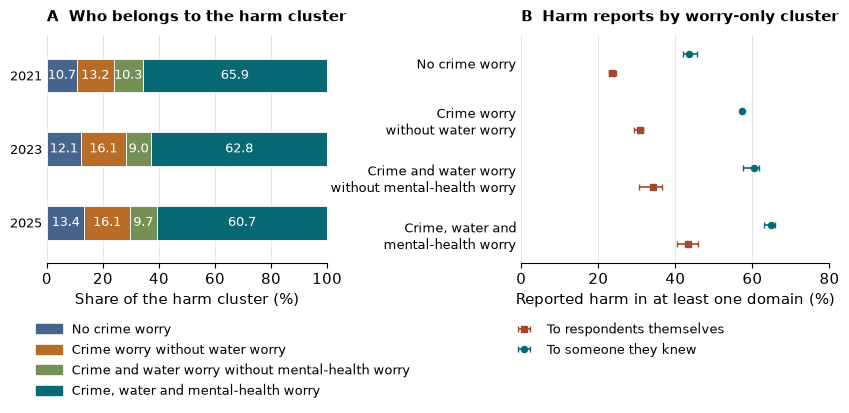

In [10]:
order = chart_order
colors = ['#b76c28', '#47658c', '#086975', '#749054']
plt.rcParams.update({'font.size': 10.5, 'pdf.fonttype': 42, 'axes.spines.top': False,
                     'axes.spines.right': False})
fig, (left, right) = plt.subplots(1, 2, figsize=(8.6, 4.0),
                                 gridspec_kw={'width_ratios': [1, 1.1]})
for i, wave in enumerate(matched_years):
    start = 0
    for w in order:
        v = 100 * composition[i][w]
        left.barh(i, v, left=start, color=colors[w], height=.46, edgecolor='white', linewidth=.6)
        left.text(start + v/2, i, f'{v:.1f}', ha='center', va='center', color='white', fontsize=9.2)
        start += v
left.set(xlim=(0,100), yticks=range(3), yticklabels=matched_years,
         xlabel='Share of the harm cluster (%)', ylim=(2.55,-.55))
left.set_title('A  Who belongs to the harm cluster', loc='left',
               fontweight='bold', fontsize=11, pad=10)
legend_titles = ['No crime worry', 'Crime worry without water worry',
                 'Crime and water worry without mental-health worry',
                 'Crime, water and mental-health worry']
left.legend([plt.Rectangle((0,0),1,1,color=colors[k]) for k in order], legend_titles,
            loc='upper left', bbox_to_anchor=(-.08,-.21), frameon=False, fontsize=9.2)

values = results['harm_original_rates'].query("scope == 'development'")[outcome_names].to_numpy().reshape(3, 4, 4)
short = ['No crime worry', 'Crime worry\nwithout water worry',
         'Crime and water worry\nwithout mental-health worry', 'Crime, water and\nmental-health worry']
for j, (color, marker, label, shift) in enumerate([
    ('#a14a2b', 's', 'To respondents themselves', .16),
    ('#086975', 'o', 'To someone they knew', -.16),
]):
    v = values[:, order, j]
    means = v.mean(axis=0)
    right.errorbar(means, np.arange(4)+shift, xerr=[means-v.min(axis=0), v.max(axis=0)-means],
                   color=color, fmt=marker, ms=4.4, capsize=2.4, linewidth=1.2, label=label)
right.set(yticks=range(4), yticklabels=short, xlim=(0,80), ylim=(3.5,-.5),
          xlabel='Reported harm in at least one domain (%)')
right.set_title('B  Harm reports by worry-only cluster', loc='left', fontweight='bold', fontsize=11, pad=10)
right.legend(loc='upper left', bbox_to_anchor=(-.07,-.21), frameon=False, fontsize=9.2)
for ax in (left,right):
    ax.set_axisbelow(True)
    ax.grid(axis='x', color='#e4e6e8', linewidth=.7)
    ax.spines['left'].set_visible(False)
    ax.tick_params(axis='y', length=0, labelsize=9.2)
fig.subplots_adjust(left=.07, right=.98, top=.89, bottom=.32, wspace=.66)
fig.savefig(paper_dir / 'results/figure3_harm_by_worry.pdf', bbox_inches='tight', pad_inches=.065)

plt.show()

## Optional fitting from the original survey CSVs

Obtain the survey files separately from [Lloyd’s Register Foundation](https://github.com/lrfoundation/world_risk_poll_data). Put `WRP_2021.csv`, `WRP_2023.csv` and `WRP_2025.csv` in `paper/data/`, or change `RAW_WAVE_DIR` in the earlier replay settings. `assets/matched_harm_schedule.json` records the exact file checksums, parsing settings, and all 303 draw and fit seeds. The country split files select each wave’s native development frame. The matched fits do not use the held-out countries.

The code balances survey weights after each draw, aggregates identical feature vectors, and fits Lloyd’s weighted \(k\)-means with 20 initializations. A respondent draw keeps 80% within each country. A country draw keeps approximately 80%, stratified by region and income. All settings use the same draw before the next draw is selected. The full optional run fits 2,424 models and can take several minutes. It returns centres in memory and displays fresh agreement and stability summaries. The manifest records the library versions used for the saved evidence.

In [11]:
from sklearn.cluster import KMeans
from threadpoolctl import threadpool_limits


def prepare_native_wave(year, raw_dir):
    source = schedule['csv_inputs'][str(year)]
    complete, answers = read_complete_harm_wave(year, raw_dir, source['float_precision'])
    registry = pd.read_csv(assets / f'country_split_full_{year}.csv').query("country_split == 'train'")
    keep = complete.COUNTRY_ISO3.isin(registry.COUNTRY_ISO3).to_numpy()
    rows, answers = complete.loc[keep], answers[keep]
    patterns, inverse, counts = np.unique(answers, axis=0, return_inverse=True, return_counts=True)
    np.testing.assert_array_equal(patterns, five[f'native_{year}_answers'])
    np.testing.assert_array_equal(counts, five[f'native_{year}_counts'])

    countries = sorted(rows.COUNTRY_ISO3.unique())
    country = pd.Categorical(rows.COUNTRY_ISO3, categories=countries).codes
    survey_weights = rows.WGT.to_numpy()
    assert np.isfinite(survey_weights).all() and (survey_weights > 0).all()
    rows_by_country = [np.flatnonzero(country == i) for i in range(len(countries))]
    registry = registry.set_index('COUNTRY_ISO3').loc[countries].reset_index()
    strata = [g.index.to_numpy() for _, g in registry.groupby(['GlobalRegion', 'CountryIncomeLevel'], sort=True)]
    sizes = np.array([len(stratum) for stratum in strata])
    quota = np.maximum(1, np.floor(.8 * sizes).astype(int))
    target_size = round(.8 * len(countries))
    while quota.sum() < target_size:
        quota[np.where(quota < sizes, .8 * sizes - quota, -np.inf).argmax()] += 1

    designs = {}
    for d, use_harm in product((6, 5), (False, True)):
        columns = list(worry_columns[d])
        if use_harm:
            columns += list(range(6, 20))
        _, first, inverse_design = np.unique(patterns[:, columns], axis=0, return_index=True, return_inverse=True)
        designs[d, use_harm] = (np.ascontiguousarray(matched_geometry(patterns[first], d, use_harm)),
                                inverse_design)
    return dict(country=country, survey_weights=survey_weights, rows_by_country=rows_by_country,
                strata=strata, quota=quota, inverse=inverse, n_patterns=len(patterns), designs=designs)


def training_rows(data, task):
    if task['test'] == 'point':
        return np.arange(len(data['country']))
    rng = np.random.default_rng(task['sample_seed'])
    if task['test'] == 'respondents':
        return np.sort(np.concatenate([rng.choice(rows, round(.8 * len(rows)), replace=False)
                                      for rows in data['rows_by_country']]))
    selected = np.concatenate([rng.choice(stratum, size, replace=False)
                               for stratum, size in zip(data['strata'], data['quota'])])
    return np.flatnonzero(np.isin(data['country'], selected))


def fit_matched_draw(data, task):
    rows = training_rows(data, task)
    country = data['country'][rows]
    survey_weights = data['survey_weights'][rows]
    totals = np.bincount(country, weights=survey_weights)
    balanced = survey_weights / totals[country] / np.count_nonzero(totals)
    pattern_mass = np.bincount(data['inverse'][rows], weights=balanced, minlength=data['n_patterns'])
    np.testing.assert_allclose(pattern_mass.sum(), 1.)
    centres = {}
    for d, k, use_harm in matched_settings:
        design, inverse = data['designs'][d, use_harm]
        weight = np.bincount(inverse, weights=pattern_mass)
        active = weight > 0
        model = KMeans(n_clusters=k, n_init=20, max_iter=300, tol=1e-4,
                       algorithm='lloyd', random_state=task['fit_seed'])
        model.fit(design[active], sample_weight=weight[active])
        centres[setting_name(d, k, use_harm)] = model.cluster_centers_
    return centres


def refit_all_matched(raw_dir):
    waves = {year: prepare_native_wave(year, raw_dir) for year in matched_years}
    values = {key: np.empty_like(value) for key, value in matched_centres.items()}
    with threadpool_limits(limits=1):
        for i, task in enumerate(schedule['tasks'], 1):
            fits = fit_matched_draw(waves[task['year']], task)
            for name, centre in fits.items():
                key = f"{name}_{task['year']}_{task['test']}"
                values[key][task['repeat']] = centre
            if i % 50 == 0 or i == len(schedule['tasks']):
                print(f"{i}/{len(schedule['tasks'])} draws fitted")
    return values

In [12]:
RUN_MATCHED_FITS = False

if RUN_MATCHED_FITS:
    new_centres = refit_all_matched(RAW_WAVE_DIR)
    new_ari, new_stability, new_cluster_stability = replay_matched_fits(new_centres)
    display(new_ari.query("test == 'point'").pivot(index=['worry_questions', 'clusters'],
                columns='year', values='ARI').sort_index(ascending=False).round(3))
    display(new_stability.round(3))